# Importacion de Librerias

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Carga y Exploracion de Datos

In [4]:
variables_macro = pd.read_excel('Macro Variables_Prueba_CD.xlsx')
volumen = pd.read_excel('Volume Data_prueba_CD.xlsx')

print(f'''Dataframe volumen:
El dataframe tiene {volumen.shape[0]} filas y {volumen.shape[1]} columnas.
''')
display(volumen.head(5))
print(f'''Dataframe variables_macro:
El dataframe tiene {variables_macro.shape[0]} filas y {variables_macro.shape[1]} columnas.
''')
display(variables_macro.head(5))

Dataframe volumen:
El dataframe tiene 36 filas y 5 columnas.



,Año,Mes,Volume,NR,DN
0,2023,1,139796.051369,1.616817e+07,6019
1,2023,2,158549.471359,1.896503e+07,6233
2,2023,3,221631.443417,2.594681e+07,6028
3,2023,4,187586.451825,2.207731e+07,6852
4,2023,5,198868.406978,2.324259e+07,6956


Dataframe variables_macro:
El dataframe tiene 87 filas y 5 columnas.



,date,concept,scale,frequency,value
0,2023-01-01,Broad Money,billions,annual,37.948650
1,2023-01-01,Broad Money,billions,quarterly,45.918736
2,2023-01-01,CPI,unit,annual,100.055148
3,2023-01-01,CPI,unit,quarterly,99.037360
4,2023-01-01,CPI,unit,monthly,98.744918


In [5]:
# Revision del tipo de datos y faltantes para el DataFrame de volumen
volumen.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36 entries, 0 to 35
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Año     36 non-null     int64  
 1   Mes     36 non-null     int64  
 2   Volume  36 non-null     float64
 3   NR      36 non-null     float64
 4   DN      36 non-null     int64  
dtypes: float64(2), int64(3)
memory usage: 1.5 KB


In [6]:
#  Revision del tipo de datos y faltantes para el DataFrame de variables macroeconomicas
variables_macro.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 87 entries, 0 to 86
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   date       87 non-null     datetime64[ns]
 1   concept    87 non-null     object        
 2   scale      87 non-null     object        
 3   frequency  87 non-null     object        
 4   value      87 non-null     float64       
dtypes: datetime64[ns](1), float64(1), object(3)
memory usage: 3.5+ KB


In [7]:
# Revision de cuantos años y meses tenemos disponibles con informacion del volumen
volumen.groupby(['Año','Mes']).agg({'Volume':'sum'}).reset_index()

,Año,Mes,Volume
0,2023,1,139796.051369
1,2023,2,158549.471359
2,2023,3,221631.443417
3,2023,4,187586.451825
4,2023,5,198868.406978
5,2023,6,194688.737361
6,2023,7,163291.793902
7,2023,8,164963.546272
8,2023,9,184913.442942
9,2023,10,174705.506005


*Tenemos información de volumen mensual para 3 años (2023-2025)*

In [8]:
# Creacion de Columnas Año y Mes en el DataFrame de variables macroeconomicas
variables_macro = variables_macro.assign(
    Año = pd.to_datetime(variables_macro['date']).dt.year,
    Mes = pd.to_datetime(variables_macro['date']).dt.month
)

# Revision de cuantos años y meses tenemos disponibles con informacion de variables macroeconomicas
display(variables_macro.groupby(['Año','Mes'])['concept'].unique().reset_index())

,Año,Mes,concept
0,2023,1,"[Broad Money, CPI, GDP, Savings, Unemployment ..."
1,2023,2,[CPI]
2,2023,3,[CPI]
3,2023,4,"[Broad Money, CPI, GDP]"
4,2023,5,[CPI]
5,2023,6,[CPI]
6,2023,7,"[Broad Money, CPI, GDP]"
7,2023,8,[CPI]
8,2023,9,[CPI]
9,2023,10,"[Broad Money, CPI, GDP]"


*Tenemos información de variables macroeconómicas para 3 años (2023-2025)*

In [9]:
# Revision de la temporalidad de las variables macroeconomicas

for variable in variables_macro['concept'].unique():
    data = variables_macro[variables_macro['concept'] == variable]
    print(f'Variable: {variable}')
    display(data.groupby(['Año','Mes'])['frequency'].unique().reset_index())

Variable: Broad Money


,Año,Mes,frequency
0,2023,1,"[annual, quarterly]"
1,2023,4,[quarterly]
2,2023,7,[quarterly]
3,2023,10,[quarterly]
4,2024,1,"[annual, quarterly]"
5,2024,4,[quarterly]
6,2024,7,[quarterly]
7,2024,10,[quarterly]
8,2025,1,"[quarterly, annual]"
9,2025,4,[quarterly]


Variable: CPI


,Año,Mes,frequency
0,2023,1,"[annual, quarterly, monthly]"
1,2023,2,[monthly]
2,2023,3,[monthly]
3,2023,4,"[quarterly, monthly]"
4,2023,5,[monthly]
5,2023,6,[monthly]
6,2023,7,"[monthly, quarterly]"
7,2023,8,[monthly]
8,2023,9,[monthly]
9,2023,10,"[monthly, quarterly]"


Variable: GDP


,Año,Mes,frequency
0,2023,1,"[annual, quarterly]"
1,2023,4,[quarterly]
2,2023,7,[quarterly]
3,2023,10,[quarterly]
4,2024,1,"[annual, quarterly]"
5,2024,4,[quarterly]
6,2024,7,[quarterly]
7,2024,10,[quarterly]
8,2025,1,"[annual, quarterly]"
9,2025,4,[quarterly]


Variable: Savings


,Año,Mes,frequency
0,2023,1,[annual]
1,2024,1,[annual]
2,2025,1,[annual]


Variable: Unemployment Rate


,Año,Mes,frequency
0,2023,1,[annual]
1,2024,1,[annual]
2,2025,1,[annual]


- *Las variables `Savings` y `Unemployment Rate` estan solo en temporalidad anual*
- *Las variables `Broad Money` y `GDP` esta en temportaliad trimestral y anual
- *La variable `CPI` esta en temporalidad mensual, trimestral y anual


In [10]:
# Revision variables trimestrales

for variable in ['GDP','Broad Money']:
    print(f'Variable: {variable}')
    display(variables_macro[variables_macro['concept'] == variable].groupby(['Año','Mes','frequency','scale'])['value'].sum().reset_index())

Variable: GDP


,Año,Mes,frequency,scale,value
0,2023,1,annual,billions,40.736359
1,2023,1,quarterly,billions,38.207765
2,2023,4,quarterly,billions,39.801554
3,2023,7,quarterly,billions,42.115131
4,2023,10,quarterly,billions,42.820987
5,2024,1,annual,billions,45.124823
6,2024,1,quarterly,billions,43.101433
7,2024,4,quarterly,billions,44.001074
8,2024,7,quarterly,billions,45.971930
9,2024,10,quarterly,billions,47.185175


Variable: Broad Money


,Año,Mes,frequency,scale,value
0,2023,1,annual,billions,37.948650
1,2023,1,quarterly,billions,45.918736
2,2023,4,quarterly,billions,36.831127
3,2023,7,quarterly,billions,37.959337
4,2023,10,quarterly,billions,37.445311
5,2024,1,annual,billions,38.027920
6,2024,1,quarterly,billions,37.604812
7,2024,4,quarterly,billions,38.775352
8,2024,7,quarterly,billions,38.269580
9,2024,10,quarterly,billions,37.554046


In [11]:
# Revision de la variable mensual,trimestra, anual

variables_macro[variables_macro['concept'] == 'CPI'].groupby(['Año','Mes','frequency','scale'])['value'].sum().reset_index()

,Año,Mes,frequency,scale,value
0,2023,1,annual,unit,100.055148
1,2023,1,monthly,unit,98.744918
2,2023,1,quarterly,unit,99.037360
3,2023,2,monthly,unit,99.075215
4,2023,3,monthly,unit,99.291946
5,2023,4,monthly,unit,99.367999
6,2023,4,quarterly,unit,99.501702
7,2023,5,monthly,unit,99.482510
8,2023,6,monthly,unit,99.654597
9,2023,7,monthly,unit,100.109923


- *Las variables trimestrales tienen la particularidad que tambien agregan la variable anualizada*
- *La variable `CPI` tiene la misma particualridad de las variables trimestrales, agrega una variable anualizada pero también una variable trimestral*

# Validacion de Estacionalidad del Volumen

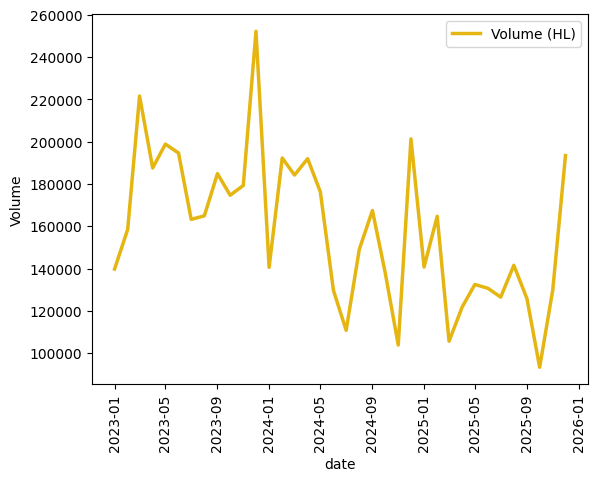

In [12]:
volumen['date'] = pd.to_datetime(
    dict(
        year=volumen["Año"],
        month=volumen["Mes"],
        day=1
    )
)

sns.lineplot(data=volumen, x="date", y="Volume", 
             color='#e5b611', linewidth=2.5, label='Volume (HL)')
plt.xticks(rotation=90)
plt.show()

C:\Users\CO588951\AppData\Local\Temp\ipykernel_21552\3147002036.py:18: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  resultado = seasonal_decompose(


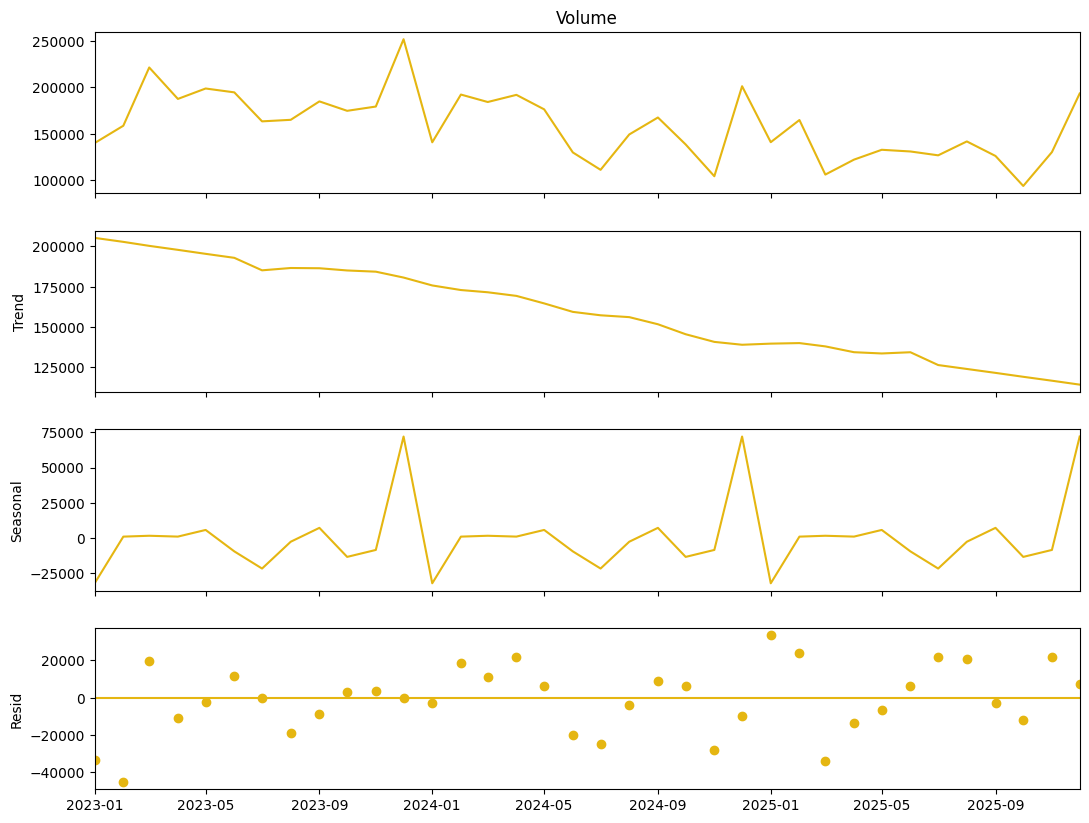

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

volume_seasonal = volumen.copy()

volume_seasonal["date"] = pd.to_datetime(
    volume_seasonal["date"]
)

volume_seasonal = (
    volume_seasonal
    .sort_values("date")
    .set_index("date")
    .asfreq("MS")
)

resultado = seasonal_decompose(
    volume_seasonal["Volume"],
    model="additive",
    period=12,
    extrapolate_trend="freq"
)

fig = resultado.plot()
fig.set_size_inches(12, 9)
for ax in fig.axes:
    for line in ax.lines:
        line.set_color("#e5b611")

plt.show()

In [14]:
import numpy as np

seasonal = resultado.seasonal.dropna()
residual = resultado.resid.dropna()

common_index = seasonal.index.intersection(
    residual.index
)

seasonal = seasonal.loc[common_index]
residual = residual.loc[common_index]

seasonal_strength = max(
    0,
    1 - (
        np.var(residual, ddof=1)
        / np.var(
            seasonal + residual,
            ddof=1
        )
    )
)

print(
    f"Fuerza estacional: {seasonal_strength:.3f}"
)

Fuerza estacional: 0.643


    MONTH_NAME  SEASONAL_EFFECT
11   Diciembre     72031.011956
8   Septiembre      7154.770533
4         Mayo      5669.990495
2        Marzo      1538.840931
3        Abril       941.446250
1      Febrero       920.605253
7       Agosto     -2704.655080
10   Noviembre     -8537.006834
5        Junio     -9561.091347
9      Octubre    -13475.259976
6        Julio    -21754.804788
0        Enero    -32223.847392


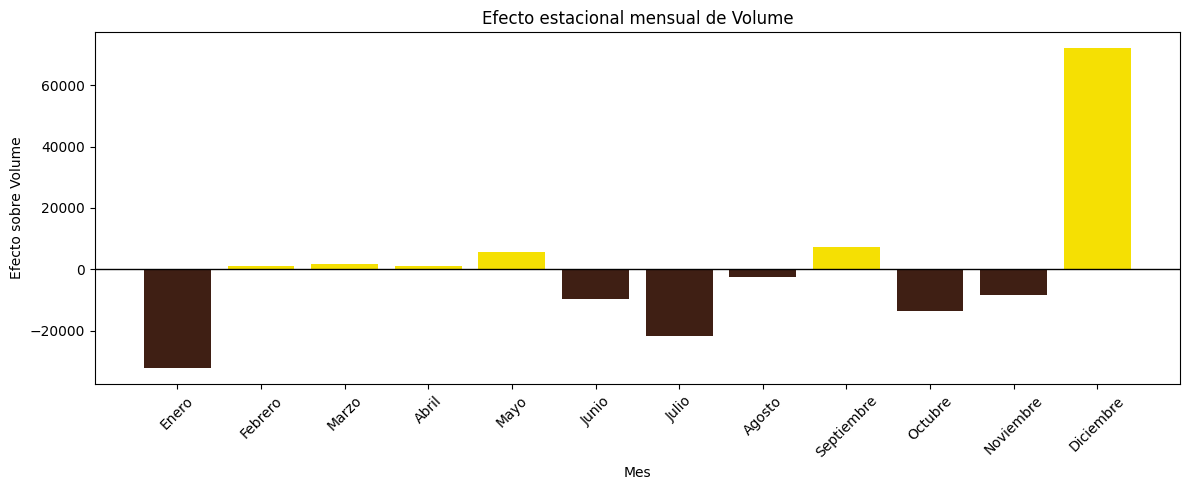

In [15]:
seasonal_monthly = (
    resultado.seasonal
    .groupby(resultado.seasonal.index.month)
    .mean()
    .rename("SEASONAL_EFFECT")
    .reset_index()
    .rename(columns={"date": "MONTH"})
)

seasonal_monthly["MONTH_NAME"] = [
    "Enero",
    "Febrero",
    "Marzo",
    "Abril",
    "Mayo",
    "Junio",
    "Julio",
    "Agosto",
    "Septiembre",
    "Octubre",
    "Noviembre",
    "Diciembre"
]

seasonal_monthly = seasonal_monthly[
    [
        "MONTH_NAME",
        "SEASONAL_EFFECT"
    ]
]

print(
    seasonal_monthly
    .sort_values(
        "SEASONAL_EFFECT",
        ascending=False
    )
)

seasonal_plot = seasonal_monthly.copy()

fig, ax = plt.subplots(figsize=(12, 5))

colors = np.where(
    seasonal_plot["SEASONAL_EFFECT"] >= 0,
    "#f5e003",
    "#3f1f14"
)

ax.bar(
    seasonal_plot["MONTH_NAME"],
    seasonal_plot["SEASONAL_EFFECT"],
    color=colors
)

ax.axhline(
    0,
    color="black",
    linewidth=1
)

ax.set_title(
    "Efecto estacional mensual de Volume"
)

ax.set_xlabel("Mes")
ax.set_ylabel("Efecto sobre Volume")
ax.tick_params(
    axis="x",
    rotation=45
)

plt.tight_layout()
plt.show()

YEAR    2023   2024   2025
MONTH                     
1      0.755  0.895  1.051
2      0.857  1.224  1.230
3      1.198  1.172  0.789
4      1.014  1.222  0.910
5      1.075  1.122  0.990
6      1.052  0.825  0.976
7      0.882  0.705  0.945
8      0.891  0.949  1.057
9      0.999  1.066  0.940
10     0.944  0.880  0.697
11     0.969  0.661  0.971
12     1.363  1.281  1.445


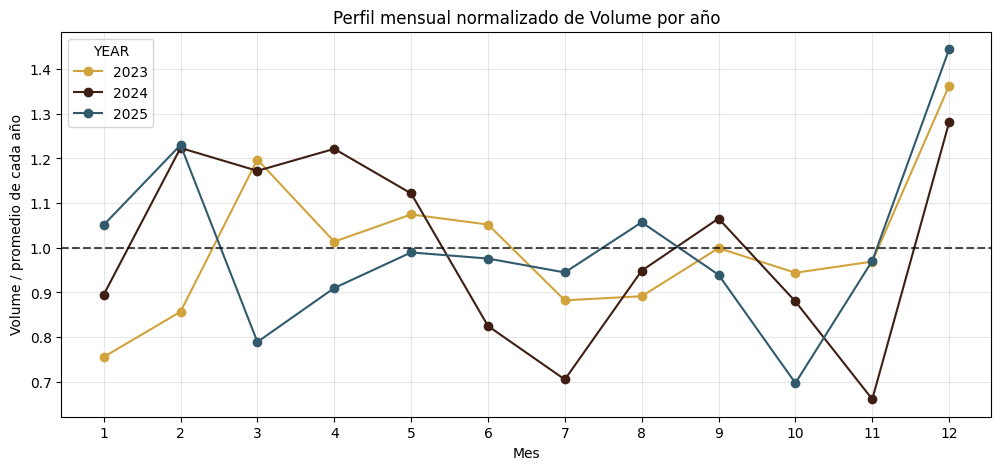

In [16]:
comparison = volumen.copy()

comparison["date"] = pd.to_datetime(
    comparison["date"]
)

comparison["YEAR"] = comparison["date"].dt.year
comparison["MONTH"] = comparison["date"].dt.month

comparison["YEAR_MEAN"] = (
    comparison
    .groupby("YEAR")["Volume"]
    .transform("mean")
)

comparison["VOLUME_INDEX"] = (
    comparison["Volume"]
    / comparison["YEAR_MEAN"]
)

profile = comparison.pivot(
    index="MONTH",
    columns="YEAR",
    values="VOLUME_INDEX"
)

print(profile.round(3))

fig, ax = plt.subplots(figsize=(12, 5))

profile.plot(
    ax=ax,
    marker="o",
    color=["#d1a33c", "#3f1f14", "#325a6d"]
)

ax.axhline(
    1,
    color="black",
    linestyle="--",
    alpha=0.7
)

ax.set_title(
    "Perfil mensual normalizado de Volume por año"
)

ax.set_xlabel("Mes")
ax.set_ylabel(
    "Volume / promedio de cada año"
)

ax.set_xticks(range(1, 13))
ax.grid(alpha=0.3)

plt.show()